# PCB/PCBA – Phát hiện khuyết tật bằng Bounding Box (YOLO / RT-DETR)
**Notebook mẫu (Nhiệm vụ B – Giai đoạn 1):** train → val → test, checkpoint định kỳ, ghi log, xuất biểu đồ & bảng.

**Cách dùng trên Kaggle**
1. Settings → *Accelerator*: GPU (T4/P100), *Internet*: On (để cài `ultralytics` và tải trọng số pretrained).
2. *Add Input* → thêm Kaggle Dataset của A (ảnh + nhãn YOLO + `data.yaml`).
3. Sửa **duy nhất** ô `CFG` bên dưới (đường dẫn dataset, mô hình, imgsz, epoch, seed), rồi *Run All*.
4. Chạy dài: *Save Version → Save & Run All (Commit)* để kết quả (`/kaggle/working`) được giữ lại sau khi hết phiên.

**Quy tắc chung của nhóm:** dùng 1 bộ chia train/val/test cố định; chọn mô hình bằng **val**, **test** chỉ để báo cáo; mọi baseline cùng imgsz/epoch/batch/seed.

In [13]:
import glob, os
import pandas as pd

# 1) Tìm data.yaml (không đoán đường dẫn)
ys = [p for p in glob.glob('/kaggle/input/**/data.yaml', recursive=True) if 'dspcbsd_yolo' in p]
print('data.yaml tìm thấy:', ys)
YAML = ys[0]
ROOT = os.path.dirname(YAML)
print('\nDATASET_DIR =', ROOT, '\nDATA_YAML   =', YAML, '\n')
print(open(YAML).read())

# 2) Đếm ảnh / nhãn theo split, kiểm tra khớp cặp
IMG = {'.jpg', '.jpeg', '.png', '.bmp'}
tot_i = tot_b = 0
for sp in ['train', 'val', 'test']:
    idir, ldir = f'{ROOT}/images/{sp}', f'{ROOT}/labels/{sp}'
    if not os.path.isdir(idir):
        print(sp, ': KHÔNG có thư mục'); continue
    imgs = {os.path.splitext(f)[0] for f in os.listdir(idir) if os.path.splitext(f)[1].lower() in IMG}
    lbls = {os.path.splitext(f)[0] for f in os.listdir(ldir)} if os.path.isdir(ldir) else set()
    boxes = sum(len([l for l in open(f'{ldir}/{s}.txt') if l.strip()]) for s in imgs & lbls)
    print(f'{sp:5s} ảnh={len(imgs):5d} nhãn={len(lbls):5d} | ảnh thiếu nhãn={len(imgs-lbls)} nhãn thiếu ảnh={len(lbls-imgs)} | bbox={boxes}')
    tot_i += len(imgs); tot_b += boxes
print(f'\nTỔNG ảnh={tot_i} (kỳ vọng ≈ 10259) | bbox={tot_b} (kỳ vọng ≈ 20276)')

# 3) Đối chiếu với báo cáo của A
for p in glob.glob('/kaggle/input/**/stage1_check_split.csv', recursive=True):
    print('\n', p); print(pd.read_csv(p).to_string(index=False))
for p in glob.glob('/kaggle/input/**/stage1_split_manifest_seed42.csv', recursive=True):
    m = pd.read_csv(p); print('\nManifest:', m.shape, '\n', m.head(5).to_string(index=False))

data.yaml tìm thấy: ['/kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo/data.yaml']

DATASET_DIR = /kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo 
DATA_YAML   = /kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo/data.yaml 

path: /kaggle/working/dspcbsd_yolo
train: images/train
val: images/val
test: images/test
nc: 9
names:
  0: SH
  1: SP
  2: SC
  3: OP
  4: MB
  5: HB
  6: CS
  7: CFO
  8: BMFO

train ảnh= 7181 nhãn= 7181 | ảnh thiếu nhãn=0 nhãn thiếu ảnh=0 | bbox=14138
val   ảnh= 1539 nhãn= 1539 | ảnh thiếu nhãn=0 nhãn thiếu ảnh=0 | bbox=3037
test  ảnh= 1539 nhãn= 1539 | ảnh thiếu nhãn=0 nhãn thiếu ảnh=0 | bbox=3101

TỔNG ảnh=10259 (kỳ vọng ≈ 10259) | bbox=20276 (kỳ vọng ≈ 20276)

 /kaggle/input/datasets/nttan28/dspcbsd-yolo-split/A_Stage1_Reports_bundle/stage1_check_split.csv
split  images  boxes  missing_label_files  empty_label_files  invalid_lines
train    7181  14138        

## 0. Module hàm dùng chung (`pcb_utils.py`)
Ô dưới ghi file module ra đĩa để notebook tự đủ. Nếu đã upload `pcb_utils.py` làm Dataset, có thể xoá ô này và `sys.path.append(...)`.

In [14]:
%%writefile pcb_utils.py
"""
pcb_utils.py  -  Hàm dùng chung cho dự án PCB/PCBA (Object Detection, YOLO/Ultralytics)
Nhiệm vụ B - Giai đoạn 1.

Nội dung
    1. Cấu hình, seed, logging, data.yaml
    2. Kiểm tra bộ dữ liệu YOLO (nhãn lỗi, rò rỉ split)
    3. Huấn luyện có checkpoint/resume + ghi log thời gian từng epoch
    4. Đánh giá val/test (P, R, F1, mAP, AP từng lớp, FPS)
    5. Thu thập dự đoán -> PR theo lớp, ROC mức phát hiện, FROC, ma trận nhầm lẫn
    6. Hàm vẽ: đường cong train, PR, ROC, confusion matrix, so sánh mô hình, ảnh dự đoán
    7. Tiện ích chuyển nhãn DeepPCB -> YOLO (chỉ dùng nếu quyết định gộp/kiểm tra chéo)

Module KHÔNG import ultralytics/torch ở đầu file, nên các hàm vẽ/thống kê chạy được ở bất kỳ máy nào.
Nhãn biểu đồ mặc định bằng tiếng Anh (đồng nhất với Ultralytics); đổi qua tham số title.
"""
from __future__ import annotations

import json
import logging
import math
import os
import random
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
_trapz = getattr(np, "trapezoid", None) or getattr(np, "trapz")


# ----------------------------------------------------------------------------
# 1. Cấu hình, seed, logging, data.yaml
# ----------------------------------------------------------------------------
def seed_everything(seed: int = 42) -> None:
    """Cố định seed cho random / numpy / torch (nếu có)."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch

        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


def setup_logger(log_path: str | Path, name: str = "pcb") -> logging.Logger:
    """Logger ghi đồng thời ra màn hình và file."""
    Path(log_path).parent.mkdir(parents=True, exist_ok=True)
    logger = logging.getLogger(name)
    logger.setLevel(logging.INFO)
    logger.handlers.clear()
    fmt = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s", "%Y-%m-%d %H:%M:%S")
    for h in (logging.FileHandler(log_path, encoding="utf-8"), logging.StreamHandler()):
        h.setFormatter(fmt)
        logger.addHandler(h)
    return logger


def disable_trackers() -> None:
    """Tắt wandb/clearml/comet... để Ultralytics không hỏi đăng nhập trên Kaggle."""
    os.environ["WANDB_DISABLED"] = "true"
    os.environ["WANDB_MODE"] = "disabled"
    try:
        from ultralytics import settings

        for k in ("wandb", "clearml", "comet", "dvc", "mlflow", "neptune", "raytune"):
            try:
                settings.update({k: False})
            except Exception:
                pass
    except ImportError:
        pass


def load_data_yaml(path: str | Path):
    """Đọc data.yaml -> (cfg, names:list[str], root:Path)."""
    path = Path(path)
    cfg = yaml.safe_load(path.read_text(encoding="utf-8"))
    names = cfg["names"]
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names, key=int)]
    root = Path(cfg.get("path", path.parent))
    if not root.is_absolute():
        root = (path.parent / root).resolve()
    return cfg, list(names), root


def make_working_yaml(src_yaml: str | Path, dst_yaml: str | Path = "/kaggle/working/data_work.yaml",
                      root: str | Path | None = None) -> str:
    """
    Dataset Kaggle nằm ở /kaggle/input (chỉ đọc) và `path` trong data.yaml của A có thể là
    đường dẫn máy cá nhân. Hàm này tạo bản sao data.yaml với `path` trỏ đúng thư mục dataset.
    """
    src_yaml = Path(src_yaml)
    cfg = yaml.safe_load(src_yaml.read_text(encoding="utf-8"))
    cfg["path"] = str(root or src_yaml.parent)
    Path(dst_yaml).parent.mkdir(parents=True, exist_ok=True)
    Path(dst_yaml).write_text(yaml.safe_dump(cfg, allow_unicode=True, sort_keys=False), encoding="utf-8")
    return str(dst_yaml)


# ----------------------------------------------------------------------------
# 2. Kiểm tra bộ dữ liệu YOLO
# ----------------------------------------------------------------------------
def label_path_for(img_path: str | Path) -> str:
    """Quy ước của Ultralytics: .../images/... -> .../labels/....txt"""
    sa, sb = f"{os.sep}images{os.sep}", f"{os.sep}labels{os.sep}"
    s = str(img_path)
    s = sb.join(s.rsplit(sa, 1)) if sa in s else s
    return os.path.splitext(s)[0] + ".txt"


def list_images(root: Path, entry) -> list[str]:
    """entry trong data.yaml: thư mục, file .txt liệt kê ảnh, hoặc list của các mục đó."""
    entries = entry if isinstance(entry, (list, tuple)) else [entry]
    out: list[str] = []
    for e in entries:
        p = Path(e)
        p = p if p.is_absolute() else root / p
        if p.is_dir():
            out += [str(f) for f in sorted(p.rglob("*")) if f.suffix.lower() in IMG_EXT]
        elif p.is_file() and p.suffix == ".txt":
            for ln in p.read_text().splitlines():
                ln = ln.strip()
                if ln:
                    q = Path(ln)
                    out.append(str(q if q.is_absolute() else root / q))
    return out


def check_dataset(data_yaml: str | Path, splits=("train", "val", "test"), max_issues: int = 20):
    """
    Kiểm tra nhanh nhãn YOLO. Trả về (df_split, df_class, issues, leaks).
      df_split : số ảnh, số bbox, file nhãn thiếu/rỗng, dòng nhãn lỗi theo từng split
      df_class : số bbox theo lớp x split
      issues   : mẫu các dòng nhãn lỗi (class id sai, tọa độ ngoài [0,1], sai số cột, ...)
      leaks    : số tên ảnh trùng giữa các split (rò rỉ dữ liệu)
    """
    cfg, names, root = load_data_yaml(data_yaml)
    nc = len(names)
    rows, cls_cols, issues, stems = [], {}, [], {}
    for sp in splits:
        if not cfg.get(sp):
            continue
        imgs = list_images(root, cfg[sp])
        stems[sp] = {Path(i).stem for i in imgs}
        n_missing = n_empty = n_bad = n_boxes = 0
        counts = np.zeros(nc, dtype=int)
        for ip in imgs:
            lp = label_path_for(ip)
            if not os.path.exists(lp):
                n_missing += 1
                continue
            lines = [l for l in Path(lp).read_text().splitlines() if l.strip()]
            if not lines:
                n_empty += 1
                continue
            for ln in lines:
                parts = ln.split()
                ok = len(parts) == 5
                if ok:
                    try:
                        c = int(float(parts[0]))
                        x, y, w, h = map(float, parts[1:])
                        ok = 0 <= c < nc and 0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1
                    except ValueError:
                        ok = False
                if not ok:
                    n_bad += 1
                    if len(issues) < max_issues:
                        issues.append(f"[{sp}] {lp}: '{ln[:70]}'")
                    continue
                counts[c] += 1
                n_boxes += 1
        rows.append(dict(split=sp, images=len(imgs), boxes=n_boxes, missing_label_files=n_missing,
                         empty_label_files=n_empty, invalid_lines=n_bad))
        cls_cols[sp] = counts
    df_split = pd.DataFrame(rows).set_index("split")
    df_class = pd.DataFrame(cls_cols, index=names)
    df_class["total"] = df_class.sum(axis=1)
    keys = list(stems)
    leaks = {f"{a}&{b}": len(stems[a] & stems[b]) for i, a in enumerate(keys) for b in keys[i + 1:]}
    return df_split, df_class, issues, leaks


# ----------------------------------------------------------------------------
# 3. Huấn luyện có checkpoint / resume + log thời gian epoch
# ----------------------------------------------------------------------------
def load_model(weights, family: str = "auto"):
    """family: 'yolo' | 'rtdetr' | 'auto' (đoán theo tên file/đường dẫn: có 'rtdetr' -> RT-DETR)."""
    from ultralytics import RTDETR, YOLO

    if family == "auto":
        family = "rtdetr" if "rtdetr" in str(weights).lower() else "yolo"
    return RTDETR(str(weights)) if family == "rtdetr" else YOLO(str(weights))


def make_epoch_logger(csv_path: str | Path, logger: logging.Logger | None = None):
    """Callback ghi thời gian từng epoch + bộ nhớ GPU. Đăng ký: model.add_callback('on_fit_epoch_end', fn)."""
    csv_path = Path(csv_path)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    state = {"t_last": time.time(), "t0": time.time()}

    def _cb(trainer):
        if trainer.epoch >= trainer.epochs:   # bỏ qua lần gọi sau validate cuối
            return
        now = time.time()
        dt = now - state["t_last"]
        
        state["t_last"] = now
        mem = 0.0
        try:
            import torch

            if torch.cuda.is_available():
                mem = torch.cuda.max_memory_allocated() / 1e9
        except ImportError:
            pass
        m = getattr(trainer, "metrics", {}) or {}
        row = dict(epoch=int(trainer.epoch) + 1, epoch_time_s=round(dt, 1),
                   elapsed_min=round((now - state["t0"]) / 60, 2), gpu_mem_gb=round(mem, 2),
                   mAP50=round(float(m.get("metrics/mAP50(B)", float("nan"))), 5),
                   mAP50_95=round(float(m.get("metrics/mAP50-95(B)", float("nan"))), 5))
        pd.DataFrame([row]).to_csv(csv_path, mode="a", header=not csv_path.exists(), index=False)
        if logger:
            logger.info("epoch %(epoch)d | %(epoch_time_s).1fs | mAP50=%(mAP50).4f | mAP50-95=%(mAP50_95).4f | gpu=%(gpu_mem_gb).1fGB", row)

    return _cb


def train_model(model_name: str, data_yaml: str, project: str, name: str, imgsz: int = 640, epochs: int = 20,
                batch: int = 16, seed: int = 42, workers: int = 2, device=0, patience: int = 100,
                fraction: float = 1.0, save_period: int = 5, resume: bool = True, family: str = "auto",
                logger: logging.Logger | None = None, extra: dict | None = None):
    """
    Huấn luyện 1 mô hình. Tự động resume nếu đã có last.pt dở dang trong project/name;
    bỏ qua train nếu đã chạy đủ epoch. Trả về (best_pt, save_dir).
    Mọi baseline phải dùng cùng imgsz/epochs/batch/seed (cấu hình chung do A chốt).
    """
    save_dir = Path(project) / name
    last, best = save_dir / "weights" / "last.pt", save_dir / "weights" / "best.pt"
    res_csv = save_dir / "results.csv"
    done = res_csv.exists() and len(pd.read_csv(res_csv)) >= epochs and best.exists()
    if done:
        (logger.info if logger else print)(f"Run '{name}' đã đủ {epochs} epoch -> bỏ qua train.")
        return str(best), save_dir

    kw = dict(data=str(data_yaml), imgsz=imgsz, epochs=epochs, batch=batch, seed=seed, deterministic=True,
              workers=workers, device=device, patience=patience, fraction=fraction, save_period=save_period,
              project=str(project), name=name, exist_ok=True, plots=True)
    kw.update(extra or {})   # extra có thể ghi đè bất kỳ tham số nào ở trên (vd deterministic=False nếu CUDA báo lỗi)
    if resume and last.exists():
        (logger.info if logger else print)(f"Tìm thấy {last} -> resume.")
        model = load_model(last, family)
        model.add_callback("on_fit_epoch_end", make_epoch_logger(save_dir / "epoch_time.csv", logger))
        model.train(resume=True)
    else:
        model = load_model(model_name, family)
        model.add_callback("on_fit_epoch_end", make_epoch_logger(save_dir / "epoch_time.csv", logger))
        model.train(**kw)
    save_dir = Path(getattr(model.trainer, "save_dir", save_dir))
    return str(save_dir / "weights" / "best.pt"), save_dir


# ----------------------------------------------------------------------------
# 4. Đánh giá val/test, FPS
# ----------------------------------------------------------------------------
def count_params(model):
    """(params triệu, GFLOPs) - GFLOPs có thể None tùy phiên bản."""
    p = sum(x.numel() for x in model.model.parameters()) / 1e6
    try:
        g = float(model.info(verbose=False)[3])
    except Exception:
        g = None
    return round(p, 2), g


def measure_fps(model, img_paths, imgsz=640, n=100, warmup=10, device=None) -> float:
    """FPS đo thật (batch=1, gồm tiền xử lý + suy luận + NMS) trên n ảnh."""
    paths = list(img_paths)[: n + warmup]
    for p in paths[:warmup]:
        model.predict(p, imgsz=imgsz, verbose=False, device=device)
    try:
        import torch

        if torch.cuda.is_available():
            torch.cuda.synchronize()
    except ImportError:
        pass
    t = time.time()
    for p in paths[warmup:]:
        model.predict(p, imgsz=imgsz, verbose=False, device=device)
    try:
        import torch

        if torch.cuda.is_available():
            torch.cuda.synchronize()
    except ImportError:
        pass
    return round(len(paths[warmup:]) / (time.time() - t), 2)


def evaluate_split(weights, data_yaml, split="test", imgsz=640, batch=16, conf=0.001, iou=0.6, device=None,
                   project="runs/eval", name=None, family="auto", plots=True) -> dict:
    """
    Chạy model.val trên split (val/test) -> dict chỉ số. Chọn mô hình bằng 'val', 'test' chỉ để báo cáo.
    Đầu ra dùng được cho make_summary_table / plot_per_class_ap.
    """
    model = load_model(weights, family)
    name = name or f"{Path(weights).parent.parent.name}_{split}"
    r = model.val(data=str(data_yaml), split=split, imgsz=imgsz, batch=batch, conf=conf, iou=iou, device=device,
                  plots=plots, project=str(project), name=name, exist_ok=True, verbose=False)
    b = r.box
    P, R = float(b.mp), float(b.mr)
    cls_names = r.names
    per_class = {cls_names[i]: dict(AP50=float("nan"), AP50_95=float("nan"), P=float("nan"), R=float("nan"))
                 for i in sorted(cls_names)}
    for j, c in enumerate(b.ap_class_index):
        per_class[cls_names[int(c)]] = dict(AP50=float(b.ap50[j]), AP50_95=float(b.ap[j]),
                                            P=float(b.p[j]), R=float(b.r[j]))
    sp = r.speed
    ms = sp.get("preprocess", 0) + sp.get("inference", 0) + sp.get("postprocess", 0)
    params, gflops = count_params(model)
    return {"Model": name, "split": split, "P": P, "R": R, "F1": 2 * P * R / (P + R + 1e-16),
            "mAP50": float(b.map50), "mAP50-95": float(b.map), "FPS_val": round(1000 / ms, 1) if ms else None,
            "Params(M)": params, "GFLOPs": gflops, "per_class": per_class, "weights": str(weights),
            "save_dir": str(getattr(r, "save_dir", ""))}


def save_json(obj, path: str | Path) -> None:
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=float), encoding="utf-8")


# ----------------------------------------------------------------------------
# 5. Thu thập dự đoán -> khớp hộp -> PR / ROC / FROC / confusion matrix
# ----------------------------------------------------------------------------
def read_yolo_labels(txt_path: str, w: int, h: int) -> np.ndarray:
    """Nhãn YOLO -> mảng (n,5): cls, x1, y1, x2, y2 (pixel)."""
    if not os.path.exists(txt_path):
        return np.zeros((0, 5))
    a = np.array([[float(v) for v in ln.split()[:5]] for ln in Path(txt_path).read_text().splitlines()
                  if len(ln.split()) >= 5], dtype=float).reshape(-1, 5)
    out = np.zeros_like(a)
    out[:, 0] = a[:, 0]
    out[:, 1] = (a[:, 1] - a[:, 3] / 2) * w
    out[:, 2] = (a[:, 2] - a[:, 4] / 2) * h
    out[:, 3] = (a[:, 1] + a[:, 3] / 2) * w
    out[:, 4] = (a[:, 2] + a[:, 4] / 2) * h
    return out


def box_iou(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """IoU từng cặp, a:(n,4) b:(m,4) xyxy -> (n,m)."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def collect_predictions(model, img_paths, imgsz=640, conf=0.001, iou=0.6, batch=16, device=None,
                        max_det=300) -> list[dict]:
    """
    Dự đoán trên danh sách ảnh với ngưỡng conf rất thấp (để vẽ được toàn bộ đường cong), kèm nhãn GT.
    Trả về list record: {path, pred:(n,6)[x1,y1,x2,y2,conf,cls], gt:(m,5)[cls,x1,y1,x2,y2]}.
    """
    img_paths = list(img_paths)
    records = []
    for i in range(0, len(img_paths), batch):
        chunk = img_paths[i:i + batch]
        results = model.predict(chunk, imgsz=imgsz, conf=conf, iou=iou, max_det=max_det, device=device,
                                verbose=False)
        for p, r in zip(chunk, results):
            h, w = r.orig_shape
            bx = r.boxes
            pred = np.concatenate([bx.xyxy.cpu().numpy(), bx.conf.cpu().numpy()[:, None],
                                   bx.cls.cpu().numpy()[:, None]], axis=1) if len(bx) else np.zeros((0, 6))
            records.append(dict(path=p, pred=pred, gt=read_yolo_labels(label_path_for(p), w, h)))
    return records


def _compute_ap(recall, precision):
    """AP nội suy 101 điểm (cùng cách tính với Ultralytics/COCO)."""
    mrec = np.concatenate(([0.0], recall, [1.0]))
    mpre = np.concatenate(([1.0], precision, [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101)
    px = np.interp(x, mrec, mpre)
    return float(_trapz(px, x)), x, px


def match_per_class(records, nc: int, iou_thr: float = 0.5) -> dict:
    """Khớp tham lam theo confidence giảm dần, từng lớp, từng ảnh. Trả {cls: scores, tp, n_gt}."""
    out = {c: dict(scores=[], tp=[], n_gt=0) for c in range(nc)}
    for rec in records:
        pred, gt = rec["pred"], rec["gt"]
        for c in range(nc):
            g = gt[gt[:, 0] == c][:, 1:]
            p = pred[pred[:, 5] == c]
            out[c]["n_gt"] += len(g)
            if len(p) == 0:
                continue
            p = p[np.argsort(-p[:, 4], kind="stable")]
            ious = box_iou(p[:, :4], g)
            used = np.zeros(len(g), dtype=bool)
            for i in range(len(p)):
                tp = False
                if len(g):
                    cand = np.where(used, -1.0, ious[i])
                    j = int(cand.argmax())
                    if cand[j] >= iou_thr:
                        used[j] = True
                        tp = True
                out[c]["scores"].append(float(p[i, 4]))
                out[c]["tp"].append(tp)
    return out


def build_curves(records, nc: int, iou_thr: float = 0.5) -> dict:
    """
    Tính PR (AP@iou_thr), ROC mức phát hiện và FROC cho từng lớp.

    LƯU Ý về ROC trong bài toán detection: không có 'true negative' theo nghĩa phân loại, nên ROC ở đây là
    ROC MỨC PHÁT HIỆN:  trục y = TP tích lũy / số GT của lớp (recall thật, đã tính cả lỗi bỏ sót);
                        trục x = FP tích lũy / tổng FP của lớp (khi quét ngưỡng confidence từ cao xuống thấp).
    AUC đo khả năng confidence xếp TP trước FP. Cần nêu rõ định nghĩa này trong báo cáo.
    FROC (recall theo số FP trên mỗi ảnh) là thước đo thay thế dễ diễn giải hơn trong kiểm tra công nghiệp.
    """
    matches = match_per_class(records, nc, iou_thr)
    n_img = max(len(records), 1)
    pr, roc, froc = {}, {}, {}
    for c in range(nc):
        n_gt = matches[c]["n_gt"]
        if n_gt == 0:
            continue
        s = np.array(matches[c]["scores"]); tp = np.array(matches[c]["tp"], dtype=bool)
        if len(s) == 0:
            x = np.linspace(0, 1, 101)
            pr[c] = dict(x=x, precision=np.zeros(101), ap=0.0, n_gt=n_gt)
            roc[c] = dict(fpr=np.array([0, 1.0]), tpr=np.array([0, 0.0]), auc=0.0)
            froc[c] = dict(fp_per_img=np.array([0.0]), recall=np.array([0.0]))
            continue
        order = np.argsort(-s, kind="stable")
        tp = tp[order]
        tpc, fpc = np.cumsum(tp), np.cumsum(~tp)
        rec, prec = tpc / n_gt, tpc / (tpc + fpc)
        ap, x, px = _compute_ap(rec, prec)
        pr[c] = dict(x=x, precision=px, ap=ap, n_gt=n_gt)
        fpr = fpc / max(fpc[-1], 1)
        fpr_f = np.concatenate(([0.0], fpr, [1.0])); tpr_f = np.concatenate(([0.0], rec, [rec[-1]]))
        roc[c] = dict(fpr=fpr_f, tpr=tpr_f, auc=float(_trapz(tpr_f, fpr_f)))
        froc[c] = dict(fp_per_img=np.concatenate(([0.0], fpc / n_img)), recall=np.concatenate(([0.0], rec)))
    return dict(pr=pr, roc=roc, froc=froc, n_images=n_img, iou_thr=iou_thr)


def confusion_matrix_det(records, nc: int, conf_thr: float = 0.25, iou_thr: float = 0.45) -> np.ndarray:
    """
    Ma trận nhầm lẫn (nc+1)x(nc+1): HÀNG = nhãn thật, CỘT = dự đoán; chỉ số nc = 'background'.
      cm[i, j]   : GT lớp i được dự đoán thành lớp j (i==j là đúng)
      cm[i, nc]  : GT lớp i bị bỏ sót (FN)
      cm[nc, j]  : dự đoán lớp j không khớp GT nào (FP / dự đoán dư)
    Khớp 1-1 theo IoU giảm dần, không phân biệt lớp ở bước khớp (giống Ultralytics) để lộ lỗi nhầm lớp.
    """
    cm = np.zeros((nc + 1, nc + 1), dtype=int)
    for rec in records:
        pred = rec["pred"][rec["pred"][:, 4] >= conf_thr] if len(rec["pred"]) else rec["pred"]
        gt = rec["gt"]
        if len(gt) == 0:
            for c in pred[:, 5].astype(int):
                cm[nc, c] += 1
            continue
        if len(pred) == 0:
            for c in gt[:, 0].astype(int):
                cm[c, nc] += 1
            continue
        iou = box_iou(gt[:, 1:], pred[:, :4])
        ij = np.argwhere(iou >= iou_thr)
        ij = ij[np.argsort(-iou[ij[:, 0], ij[:, 1]])] if len(ij) else ij
        ug, up = set(), set()
        for gi, pi in ij:
            if gi in ug or pi in up:
                continue
            ug.add(gi); up.add(pi)
            cm[int(gt[gi, 0]), int(pred[pi, 5])] += 1
        for gi in range(len(gt)):
            if gi not in ug:
                cm[int(gt[gi, 0]), nc] += 1
        for pi in range(len(pred)):
            if pi not in up:
                cm[nc, int(pred[pi, 5])] += 1
    return cm


# ----------------------------------------------------------------------------
# 6. Hàm vẽ
# ----------------------------------------------------------------------------
def _finish(fig, save_path=None, show=True, dpi=200):
    fig.tight_layout()
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)


def _read_results(csv) -> pd.DataFrame:
    df = pd.read_csv(csv)
    df.columns = [c.strip() for c in df.columns]
    return df


def plot_training_curves(results_csv, title="", save_path=None, show=True):
    """
    Biểu đồ huấn luyện từ results.csv của Ultralytics (YOLO và RT-DETR): mọi cặp train/val loss,
    Precision-Recall và mAP theo epoch; đánh dấu epoch tốt nhất theo mAP50-95.
    """
    df = _read_results(results_csv)
    x = df["epoch"] if "epoch" in df else np.arange(1, len(df) + 1)
    losses = {}
    for c in df.columns:
        if c.startswith("train/") and c.endswith("loss"):
            k = c.split("/", 1)[1]
            losses[k] = (c, f"val/{k}" if f"val/{k}" in df.columns else None)
    n = len(losses) + 2
    ncols = 3
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    best = None
    m = "metrics/mAP50-95(B)"
    if m in df:
        best = int(df[m].idxmax())
    for ax, (k, (tr, va)) in zip(axes, losses.items()):
        ax.plot(x, df[tr], label="train", lw=1.8)
        if va:
            ax.plot(x, df[va], label="val", lw=1.8)
        ax.set_title(k); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend()
    i = len(losses)
    ax = axes[i]
    for col, lab in (("metrics/precision(B)", "Precision"), ("metrics/recall(B)", "Recall")):
        if col in df:
            ax.plot(x, df[col], label=lab, lw=1.8)
    ax.set_title("Precision / Recall (val)"); ax.set_xlabel("epoch"); ax.set_ylim(0, 1.02); ax.grid(alpha=.3); ax.legend()
    ax = axes[i + 1]
    for col, lab in (("metrics/mAP50(B)", "mAP@0.5"), (m, "mAP@0.5:0.95")):
        if col in df:
            ax.plot(x, df[col], label=lab, lw=1.8)
    if best is not None:
        ax.axvline(x.iloc[best] if hasattr(x, "iloc") else x[best], color="gray", ls="--", lw=1)
        ax.set_title(f"mAP (val) - best epoch {int(x.iloc[best] if hasattr(x, 'iloc') else x[best])}: {df[m].iloc[best]:.4f}")
    else:
        ax.set_title("mAP (val)")
    ax.set_xlabel("epoch"); ax.set_ylim(0, 1.02); ax.grid(alpha=.3); ax.legend()
    for ax in axes[n:]:
        ax.axis("off")
    if title:
        fig.suptitle(title, fontsize=14, y=1.02)
    _finish(fig, save_path, show)


def plot_compare_curves(csv_dict: dict, metric="metrics/mAP50-95(B)", title=None, save_path=None, show=True):
    """So sánh 1 chỉ số theo epoch giữa nhiều mô hình. csv_dict = {tên: đường_dẫn_results.csv}."""
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for name, p in csv_dict.items():
        df = _read_results(p)
        ax.plot(df["epoch"] if "epoch" in df else np.arange(1, len(df) + 1), df[metric], label=name, lw=1.8)
    ax.set_xlabel("epoch"); ax.set_ylabel(metric); ax.grid(alpha=.3); ax.legend()
    ax.set_title(title or f"{metric} theo epoch")
    _finish(fig, save_path, show)


def plot_pr_curves(curves: dict, names, title="Precision-Recall (per class)", save_path=None, show=True):
    """Đường PR từng lớp + đường trung bình (đậm). curves = build_curves(...)."""
    fig, ax = plt.subplots(figsize=(8, 6))
    cmap = plt.get_cmap("tab10" if len(names) <= 10 else "tab20")
    aps, precs = [], []
    for c, d in curves["pr"].items():
        ax.plot(d["x"], d["precision"], color=cmap(c % cmap.N), lw=1.4, label=f"{names[c]}  {d['ap']:.3f}")
        aps.append(d["ap"]); precs.append(d["precision"])
    if precs:
        ax.plot(d["x"], np.mean(precs, axis=0), color="black", lw=3,
                label=f"all classes  mAP@{curves['iou_thr']:.2f} = {np.mean(aps):.3f}")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.grid(alpha=.3); ax.set_title(title)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
    _finish(fig, save_path, show)
    return {names[c]: d["ap"] for c, d in curves["pr"].items()}


def plot_roc_curves(curves: dict, names, title="ROC (detection-level, per class)", save_path=None, show=True):
    """ROC mức phát hiện từng lớp (định nghĩa xem build_curves). Trả {lớp: AUC}."""
    fig, ax = plt.subplots(figsize=(8, 6))
    cmap = plt.get_cmap("tab10" if len(names) <= 10 else "tab20")
    aucs = {}
    for c, d in curves["roc"].items():
        ax.plot(d["fpr"], d["tpr"], color=cmap(c % cmap.N), lw=1.6, label=f"{names[c]}  AUC={d['auc']:.3f}")
        aucs[names[c]] = d["auc"]
    ax.set_xlabel("False positive rate (FP / total FP)"); ax.set_ylabel("True positive rate (TP / #GT)")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(alpha=.3)
    ax.set_title(f"{title}\nmean AUC = {np.mean(list(aucs.values())):.3f}" if aucs else title)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
    _finish(fig, save_path, show)
    return aucs


def plot_froc_curves(curves: dict, names, max_fp=2.0, title="FROC (recall vs FP per image)", save_path=None, show=True):
    """Recall theo số FP trung bình trên mỗi ảnh (thước đo thay thế cho ROC)."""
    fig, ax = plt.subplots(figsize=(8, 6))
    cmap = plt.get_cmap("tab10" if len(names) <= 10 else "tab20")
    for c, d in curves["froc"].items():
        ax.plot(d["fp_per_img"], d["recall"], color=cmap(c % cmap.N), lw=1.6, label=names[c])
    ax.set_xlim(0, max_fp); ax.set_ylim(0, 1.02); ax.set_xlabel("FP per image"); ax.set_ylabel("Recall")
    ax.grid(alpha=.3); ax.set_title(title)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
    _finish(fig, save_path, show)


def plot_confusion_matrix(cm: np.ndarray, names, normalize=True, title="Confusion matrix",
                          save_path=None, show=True):
    """cm từ confusion_matrix_det (hàng = thật, cột = dự đoán, nhãn cuối = background)."""
    labels = list(names) + ["background"]
    n = len(labels)
    mat = cm.astype(float)
    if normalize:
        mat = mat / np.maximum(mat.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(max(6, 0.9 * n + 2), max(5, 0.8 * n + 1.5)))
    im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(n)); ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(n)); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    thr = mat.max() / 2 if mat.max() > 0 else 1
    for i in range(n):
        for j in range(n):
            if cm[i, j] == 0 and normalize:
                continue
            txt = f"{mat[i, j]:.2f}" if normalize else f"{cm[i, j]}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=8, color="white" if mat[i, j] > thr else "black")
    ax.set_title(title + (" (row-normalized)" if normalize else " (counts)"))
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    _finish(fig, save_path, show)


SUMMARY_COLS = ["Model", "P", "R", "F1", "mAP50", "mAP50-95", "FPS", "Params(M)", "GFLOPs"]


def make_summary_table(results: dict | list, decimals=4, save_csv=None, save_md=None) -> pd.DataFrame:
    """
    Bảng tổng hợp nhiều mô hình. results = {tên: dict từ evaluate_split (+ 'FPS' nếu đo bằng measure_fps)}
    hoặc list các dict có khóa 'Model'. Hiển thị tô màu: display(df.style.highlight_max(...)) - xem style_summary.
    """
    items = [dict(v, Model=k) for k, v in results.items()] if isinstance(results, dict) else list(results)
    rows = []
    for r in items:
        row = {c: r.get(c) for c in SUMMARY_COLS}
        if row["FPS"] is None:
            row["FPS"] = r.get("FPS_val")
        rows.append(row)
    df = pd.DataFrame(rows).dropna(axis=1, how="all")
    num = df.select_dtypes("number").columns
    df[num] = df[num].round(decimals)
    if save_csv:
        Path(save_csv).parent.mkdir(parents=True, exist_ok=True)
        df.to_csv(save_csv, index=False)
    if save_md:
        best = {c: df[c].max() for c in ("P", "R", "F1", "mAP50", "mAP50-95", "FPS") if c in df}
        lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
        for _, r in df.iterrows():
            cells = []
            for c in df.columns:
                v = r[c]
                s = "-" if pd.isna(v) else (f"{v:.{decimals}f}" if c in ("P", "R", "F1", "mAP50", "mAP50-95") else f"{v:g}" if isinstance(v, float) else str(v))
                cells.append(f"**{s}**" if c in best and not pd.isna(v) and v == best[c] else s)
            lines.append("| " + " | ".join(cells) + " |")
        Path(save_md).write_text("\n".join(lines), encoding="utf-8")
    return df


def style_summary(df: pd.DataFrame):
    """Styler tô xanh giá trị tốt nhất mỗi cột chỉ số (dùng trong Jupyter)."""
    cols = [c for c in ("P", "R", "F1", "mAP50", "mAP50-95", "FPS") if c in df]
    return df.style.highlight_max(subset=cols, color="#c6efce").format(precision=4)


def plot_model_comparison(df: pd.DataFrame, metrics=("P", "R", "mAP50", "mAP50-95"), title="Model comparison",
                          save_path=None, show=True):
    """Cột nhóm so sánh các chỉ số giữa mô hình; nếu có cột FPS thì thêm 1 panel FPS."""
    metrics = [m for m in metrics if m in df]
    has_fps = "FPS" in df and df["FPS"].notna().any()
    fig, axes = plt.subplots(1, 2 if has_fps else 1, figsize=(11 if has_fps else 8, 4.8),
                             gridspec_kw=dict(width_ratios=[3, 1]) if has_fps else None)
    axes = np.atleast_1d(axes)
    ax = axes[0]
    w = 0.8 / max(len(df), 1)
    xs = np.arange(len(metrics))
    for i, (_, r) in enumerate(df.iterrows()):
        vals = [r[m] for m in metrics]
        bars = ax.bar(xs + i * w - 0.4 + w / 2, vals, w, label=r["Model"])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, f"{v:.3f}", ha="center", fontsize=7, rotation=90)
    ax.set_xticks(xs); ax.set_xticklabels(metrics); ax.set_ylim(0, 1.1); ax.grid(axis="y", alpha=.3)
    ax.legend(fontsize=8); ax.set_title(title)
    if has_fps:
        axes[1].bar(df["Model"], df["FPS"], color=[plt.get_cmap("tab10")(i) for i in range(len(df))])
        axes[1].set_title("FPS"); axes[1].tick_params(axis="x", rotation=45); axes[1].grid(axis="y", alpha=.3)
    _finish(fig, save_path, show)


def per_class_table(results: dict, key="AP50") -> pd.DataFrame:
    """results={model: dict evaluate_split} -> DataFrame (lớp x mô hình) của AP50 hoặc AP50_95."""
    return pd.DataFrame({m: {c: v[key] for c, v in r["per_class"].items()} for m, r in results.items()})


def plot_per_class_ap(table: pd.DataFrame, title="AP per class", save_path=None, show=True):
    """Heatmap AP theo lớp (hàng) x mô hình (cột) để phân tích lớp mạnh/yếu."""
    fig, ax = plt.subplots(figsize=(1.6 * len(table.columns) + 3, 0.6 * len(table) + 2))
    im = ax.imshow(table.values.astype(float), cmap="YlGn", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(table.shape[1])); ax.set_xticklabels(table.columns, rotation=30, ha="right")
    ax.set_yticks(range(table.shape[0])); ax.set_yticklabels(table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            ax.text(j, i, "n/a" if pd.isna(v) else f"{v:.3f}", ha="center", va="center", fontsize=8)
    ax.set_title(title); fig.colorbar(im, ax=ax, fraction=0.04)
    _finish(fig, save_path, show)


def show_predictions(model, img_paths, conf=0.25, imgsz=640, ncols=3, titles=None, save_path=None, show=True):
    """Lưới ảnh dự đoán (hộp + lớp + confidence) bằng bộ vẽ của Ultralytics."""
    img_paths = list(img_paths)
    res = model.predict(img_paths, imgsz=imgsz, conf=conf, verbose=False)
    nrows = math.ceil(len(res) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 5.5 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for i, (ax, r) in enumerate(zip(axes, res)):
        ax.imshow(r.plot()[..., ::-1]); ax.axis("off")
        ax.set_title(titles[i] if titles else Path(r.path).name, fontsize=9)
    for ax in axes[len(res):]:
        ax.axis("off")
    _finish(fig, save_path, show)


def plot_gt_vs_pred(model, img_path, names, conf=0.25, imgsz=640, save_path=None, show=True):
    """Hai khung cạnh nhau: nhãn thật (xanh lá) và dự đoán (đỏ). Dùng cho phân tích lỗi bỏ sót/dư/nhầm lớp."""
    import matplotlib.patches as mp
    from PIL import Image

    img = Image.open(img_path).convert("RGB")
    w, h = img.size
    gt = read_yolo_labels(label_path_for(img_path), w, h)
    r = model.predict(img_path, imgsz=imgsz, conf=conf, verbose=False)[0]
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
    for ax, t in zip(axes, ("Ground truth", f"Prediction (conf >= {conf})")):
        ax.imshow(img); ax.axis("off"); ax.set_title(t)
    for c, x1, y1, x2, y2 in gt:
        axes[0].add_patch(mp.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=1.8))
        axes[0].text(x1, y1 - 3, names[int(c)], color="lime", fontsize=8, weight="bold")
    for (x1, y1, x2, y2), cf, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy()):
        axes[1].add_patch(mp.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=1.8))
        axes[1].text(x1, y1 - 3, f"{names[int(c)]} {cf:.2f}", color="red", fontsize=8, weight="bold")
    _finish(fig, save_path, show)


def evaluate_curves_for_model(model, data_yaml, split="test", imgsz=640, device=None, out_dir="figures",
                              tag="model", conf_cm=0.25, show=True) -> dict:
    """
    Tiện ích 1 lệnh: thu dự đoán trên split -> vẽ & lưu PR, ROC, FROC, confusion matrix (đếm + chuẩn hóa).
    Trả về dict {'AP50_custom', 'AUC', 'cm'} để đối chiếu với số của Ultralytics.
    """
    cfg, names, root = load_data_yaml(data_yaml)
    imgs = list_images(root, cfg[split])
    recs = collect_predictions(model, imgs, imgsz=imgsz, device=device)
    curves = build_curves(recs, len(names), 0.5)
    out = Path(out_dir)
    ap = plot_pr_curves(curves, names, title=f"PR curves - {tag} ({split})", save_path=out / f"{tag}_{split}_pr.png", show=show)
    auc = plot_roc_curves(curves, names, title=f"ROC - {tag} ({split})", save_path=out / f"{tag}_{split}_roc.png", show=show)
    plot_froc_curves(curves, names, title=f"FROC - {tag} ({split})", save_path=out / f"{tag}_{split}_froc.png", show=show)
    cm = confusion_matrix_det(recs, len(names), conf_thr=conf_cm)
    plot_confusion_matrix(cm, names, True, f"Confusion matrix - {tag} ({split})", out / f"{tag}_{split}_cm_norm.png", show)
    plot_confusion_matrix(cm, names, False, f"Confusion matrix - {tag} ({split})", out / f"{tag}_{split}_cm_count.png", show)
    return dict(AP50_custom=ap, AUC=auc, cm=cm.tolist())


# ----------------------------------------------------------------------------
# 7. Tiện ích DeepPCB -> YOLO (chỉ cần khi kiểm tra chéo / gộp dữ liệu)
# ----------------------------------------------------------------------------
DEEPPCB_ID2NAME = {1: "open", 2: "short", 3: "mousebite", 4: "spur", 5: "copper", 6: "pin-hole"}
# Gợi ý ánh xạ sang 5 lớp tương đồng của DsPCBSD+ (SỬA theo tên lớp thực tế trong data.yaml của A).
# pin-hole KHÔNG ánh xạ (None): không có lớp tương đương rõ ràng, tránh nhãn sai.
DEEPPCB_TO_DSPCBSD = {"open": "OP", "short": "SH", "mousebite": "MB", "spur": "SP", "copper": "SC", "pin-hole": None}


def convert_deeppcb_annotation(txt_path, target_names: list[str], name_map: dict = DEEPPCB_TO_DSPCBSD,
                               w: int = 640, h: int = 640) -> list[str]:
    """
    Nhãn DeepPCB (mỗi dòng: x1,y1,x2,y2,type; type 1..6, 0 là nền) -> các dòng YOLO (cls cx cy w h chuẩn hóa).
    target_names = danh sách tên lớp trong data.yaml đích. Lớp ánh xạ None/không có trong đích sẽ bị bỏ.
    """
    out = []
    for ln in Path(txt_path).read_text().splitlines():
        p = [v for v in re.split(r"[,\s]+", ln.strip()) if v]
        if len(p) < 5:
            continue
        x1, y1, x2, y2, t = float(p[0]), float(p[1]), float(p[2]), float(p[3]), int(float(p[4]))
        tgt = name_map.get(DEEPPCB_ID2NAME.get(t, ""))
        if tgt is None or tgt not in target_names:
            continue
        cx, cy = (x1 + x2) / 2 / w, (y1 + y2) / 2 / h
        bw, bh = (x2 - x1) / w, (y2 - y1) / h
        out.append(f"{target_names.index(tgt)} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}")
    return out

Overwriting pcb_utils.py


In [15]:
# !pip install -q -U ultralytics
!pip install -q ultralytics==8.4.218
import ultralytics, torch, sys, os, platform
sys.path.append('.')
import importlib, pcb_utils as U
importlib.reload(U)
import pandas as pd
from pathlib import Path
from IPython.display import display
ultralytics.checks()
print('ultralytics', ultralytics.__version__, '| torch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'KHÔNG CÓ')

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 5643.9/8156.9 GB disk)
ultralytics 8.4.218 | torch 2.11.0+cu130 | GPU: Tesla T4


## 1. Cấu hình (chỉ sửa ô này)
> Khi A chốt cấu hình chung (Giai đoạn 2), cập nhật `IMGSZ`, `EPOCHS`, `BATCH`, `SEED` rồi giữ nguyên cho mọi baseline.

In [16]:
CFG = dict(
    # ---- Dữ liệu (A bàn giao) ----
    DATASET_DIR = '/kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo',
    DATA_YAML   = '/kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo/data.yaml',
    # ---- Mô hình ----
    MODEL  = 'rtdetr-l.pt',     # 'yolov8s.pt' | 'yolo11s.pt' | file .yaml (kiến trúc cải tiến)
    FAMILY = 'rtdetr',          # đặt rõ 'rtdetr' cho chắc; khi chạy YOLO thì đổi lại 'yolo' hoặc 'auto'
    # ---- Huấn luyện (cấu hình chung do A chốt) ----
    IMGSZ=640, EPOCHS=20, BATCH=16, SEED=42, WORKERS=2, DEVICE=0, PATIENCE=100,
    FRACTION=1.0,              # CHẠY THỬ - trả về 1.0 khi chạy chính thức
    SAVE_PERIOD=5,              # CHẠY THỬ - khi chạy chính thức dùng 5
    RESUME=True,                # tự resume nếu phiên trước bị ngắt
    TRAIN_EXTRA=dict(),         # tham số bổ sung cho Ultralytics, vd dict(cos_lr=True, mosaic=1.0)
    # ---- Đầu ra ----
    RUN_NAME='yolov8s_640_s42',  # CHẠY THỬ - chính thức: rtdetr_l_<imgsz>_s<seed>
    PROJECT='/kaggle/working/runs',
    OUT_DIR='/kaggle/working/results',
)
Path(CFG['OUT_DIR']).mkdir(parents=True, exist_ok=True)
log = U.setup_logger(f"{CFG['OUT_DIR']}/{CFG['RUN_NAME']}.log")
U.seed_everything(CFG['SEED']); U.disable_trackers()
log.info('CFG: %s', CFG)

2026-11-25 14:15:55 | INFO | CFG: {'DATASET_DIR': '/kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo', 'DATA_YAML': '/kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo/data.yaml', 'MODEL': 'rtdetr-l.pt', 'FAMILY': 'rtdetr', 'IMGSZ': 640, 'EPOCHS': 2, 'BATCH': 16, 'SEED': 42, 'WORKERS': 2, 'DEVICE': 0, 'PATIENCE': 100, 'FRACTION': 0.05, 'SAVE_PERIOD': 1, 'RESUME': True, 'TRAIN_EXTRA': {}, 'RUN_NAME': 'smoke_rtdetr_l', 'PROJECT': '/kaggle/working/runs', 'OUT_DIR': '/kaggle/working/results'}


In [17]:
from pathlib import Path

print("DATASET_DIR exists:", Path(CFG['DATASET_DIR']).exists())
print("DATA_YAML exists:", Path(CFG['DATA_YAML']).exists())

print("\nDATASET_DIR:")
print(CFG['DATASET_DIR'])

print("\nDATA_YAML:")
print(CFG['DATA_YAML'])

if Path(CFG['DATASET_DIR']).exists():
    print("\nDataset contents:")
    for item in Path(CFG['DATASET_DIR']).iterdir():
        print(item.name)

if Path(CFG['DATA_YAML']).exists():
    print("\n--- data.yaml content ---")
    print(Path(CFG['DATA_YAML']).read_text())

DATASET_DIR exists: True
DATA_YAML exists: True

DATASET_DIR:
/kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo

DATA_YAML:
/kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo/data.yaml

Dataset contents:
data.yaml
images
labels

--- data.yaml content ---
path: /kaggle/working/dspcbsd_yolo
train: images/train
val: images/val
test: images/test
nc: 9
names:
  0: SH
  1: SP
  2: SC
  3: OP
  4: MB
  5: HB
  6: CS
  7: CFO
  8: BMFO



## 2. Kiểm tra dữ liệu (chạy trước khi train)
Đếm ảnh/bbox theo split và lớp, phát hiện nhãn lỗi (class id sai, tọa độ ngoài [0,1]), file nhãn thiếu/rỗng và **rò rỉ dữ liệu** giữa các split. Kết quả cũng là cách B đối chiếu bàn giao của A.

In [18]:
assert os.path.exists(CFG['DATA_YAML']), f"Không thấy {CFG['DATA_YAML']} – kiểm tra lại tên dataset ở CFG"
DATA_YAML = U.make_working_yaml(CFG['DATA_YAML'], '/kaggle/working/data_work.yaml', root=CFG['DATASET_DIR'])
cfg_y, NAMES, ROOT = U.load_data_yaml(DATA_YAML)
print('Số lớp:', len(NAMES), NAMES)
df_split, df_class, issues, leaks = U.check_dataset(DATA_YAML)
display(df_split); display(df_class)
print('Rò rỉ giữa split (số tên ảnh trùng):', leaks)
print('Nhãn lỗi (mẫu):', issues if issues else 'không có')

Số lớp: 9 ['SH', 'SP', 'SC', 'OP', 'MB', 'HB', 'CS', 'CFO', 'BMFO']


,images,boxes,missing_label_files,empty_label_files,invalid_lines
split,,,,,
train,7181,14138,0,0,0
val,1539,3037,0,0,0
test,1539,3101,0,0,0


,train,val,test,total
SH,652,146,117,915
SP,3190,663,731,4584
SC,1116,238,239,1593
OP,1221,276,273,1770
MB,1768,365,396,2529
HB,2030,417,436,2883
CS,1723,388,379,2490
CFO,1253,301,278,1832
BMFO,1185,243,252,1680


Rò rỉ giữa split (số tên ảnh trùng): {'train&val': 0, 'train&test': 0, 'val&test': 0}
Nhãn lỗi (mẫu): không có


## 3. Huấn luyện
- Có **checkpoint**: `weights/last.pt` mỗi epoch, `epoch{N}.pt` theo `SAVE_PERIOD`, `best.pt` theo fitness.
- Có **log**: file `.log` (Python logging), `results.csv` (Ultralytics) và `epoch_time.csv` (thời gian/epoch – dùng cho bảng ước lượng GPU của A).
- Phiên bị ngắt: chạy lại ô này, hàm tự **resume** từ `last.pt`; đã đủ epoch thì bỏ qua.
- Chạy thử (smoke test): đặt `FRACTION=0.05`, `EPOCHS=2`.

In [19]:
best_pt, save_dir = U.train_model(
    CFG['MODEL'], DATA_YAML, CFG['PROJECT'], CFG['RUN_NAME'],
    imgsz=CFG['IMGSZ'], epochs=CFG['EPOCHS'], batch=CFG['BATCH'], seed=CFG['SEED'], workers=CFG['WORKERS'],
    device=CFG['DEVICE'], patience=CFG['PATIENCE'], fraction=CFG['FRACTION'], save_period=CFG['SAVE_PERIOD'],
    resume=CFG['RESUME'], family=CFG['FAMILY'], logger=log, extra=CFG['TRAIN_EXTRA'])
log.info('best.pt = %s | save_dir = %s', best_pt, save_dir)
display(pd.read_csv(save_dir / 'epoch_time.csv').tail(3)) if (save_dir / 'epoch_time.csv').exists() else None

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_work.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.05, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_rtdetr_l, nbs=64, nms=None, opset=None, optimize=Fa

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/2      12.4G      1.557      43.06      1.001         20        640: 100% ━━━━━━━━━━━━ 23/23 1.3s/it 30.3s1.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 49/49 1.5it/s 32.6s0.6ss
                   all       1539       3037      0.226    0.00806   0.000538   0.000178


2026-11-25 14:17:20 | INFO | epoch 1 | 73.7s | mAP50=0.0005 | mAP50-95=0.0002 | gpu=12.5GB



      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        2/2      12.7G      1.104      6.543     0.7467          9        640: 100% ━━━━━━━━━━━━ 23/23 1.0it/s 22.8s0.8ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 49/49 1.5it/s 32.1s0.7ss
                   all       1539       3037     0.0077       0.14    0.00363    0.00155


2026-11-25 14:18:18 | INFO | epoch 2 | 57.7s | mAP50=0.0036 | mAP50-95=0.0015 | gpu=12.5GB



2 epochs completed in 0.034 hours.
Optimizer stripped from /kaggle/working/runs/smoke_rtdetr_l/weights/last.pt, 66.2MB
Optimizer stripped from /kaggle/working/runs/smoke_rtdetr_l/weights/best.pt, 66.2MB

Validating /kaggle/working/runs/smoke_rtdetr_l/weights/best.pt...
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 315 layers, 32,002,235 parameters, 0 gradients, 105.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 49/49 1.6it/s 30.5s0.6ss
                   all       1539       3037     0.0077      0.141    0.00363    0.00156
                    SH         89        146   4.31e-05     0.0137   9.74e-07   1.34e-07
                    SP        323        663     0.0239      0.133    0.00476    0.00153
                    SC        204        238     0.0373      0.269     0.0219    0.00983
                    OP        225        276   3.97e-05    0.00362  

2026-11-25 14:18:56 | INFO | best.pt = /kaggle/working/runs/smoke_rtdetr_l/weights/best.pt | save_dir = /kaggle/working/runs/smoke_rtdetr_l


,epoch,epoch_time_s,elapsed_min,gpu_mem_gb,mAP50,mAP50_95
0,1,73.7,1.23,12.49,0.00054,0.00018
1,2,57.7,2.19,12.50,0.00363,0.00155


## 4. Biểu đồ huấn luyện

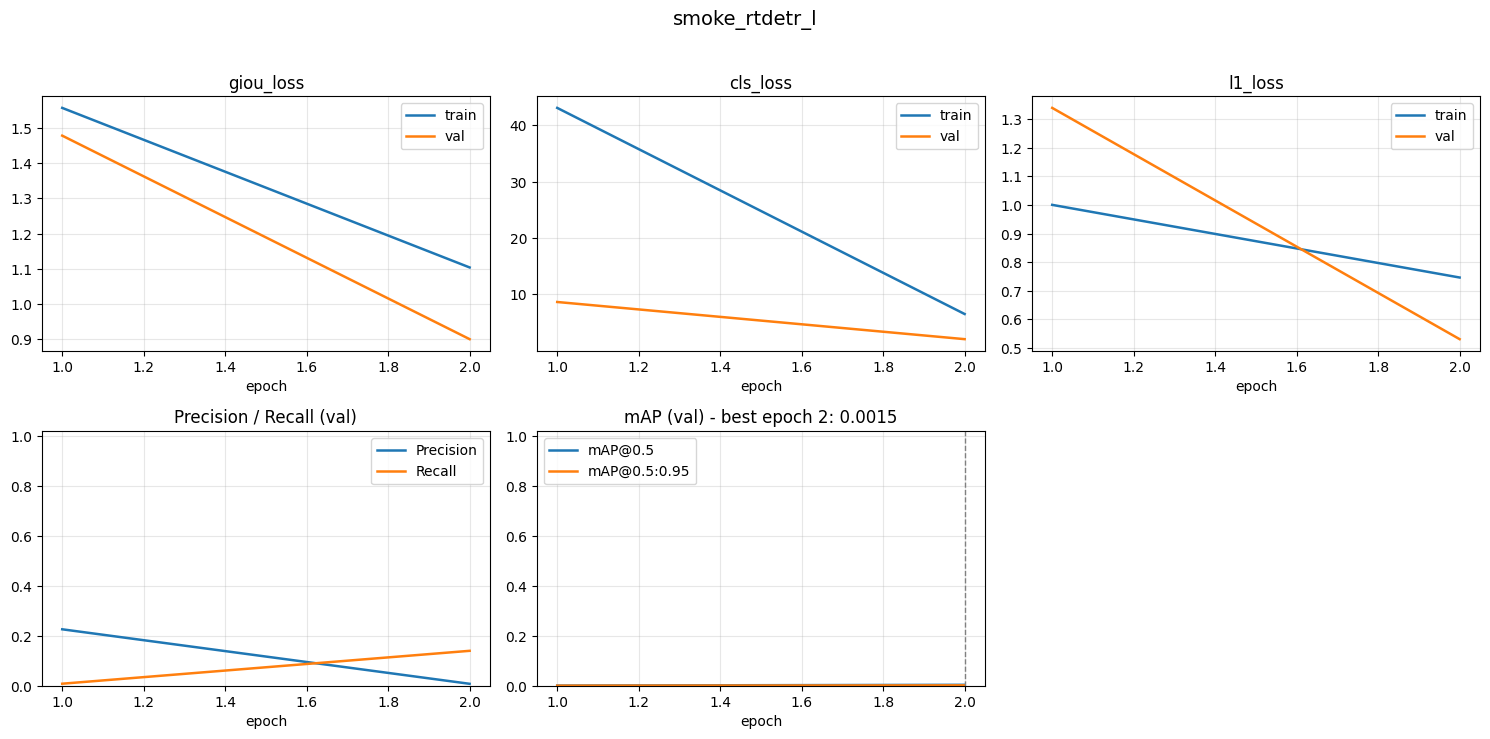

In [20]:
FIG = Path(CFG['OUT_DIR']) / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
U.plot_training_curves(save_dir / 'results.csv', title=CFG['RUN_NAME'], save_path=FIG / f"{CFG['RUN_NAME']}_train.png")

## 5. Đánh giá trên val và test
`evaluate_split` trả P, R, F1, mAP50, mAP50-95, AP từng lớp, tham số, GFLOPs. **FPS** đo riêng (batch=1, gồm tiền/hậu xử lý). Chọn mô hình bằng *val*; *test* chỉ để báo cáo.

In [21]:
EV = dict(imgsz=CFG['IMGSZ'], batch=CFG['BATCH'], family=CFG['FAMILY'], project=Path(CFG['OUT_DIR']) / 'eval')
res_val  = U.evaluate_split(best_pt, DATA_YAML, 'val',  name=f"{CFG['RUN_NAME']}_val",  **EV)
res_test = U.evaluate_split(best_pt, DATA_YAML, 'test', name=f"{CFG['RUN_NAME']}_test", **EV)

model = U.load_model(best_pt, CFG['FAMILY'])
test_imgs = U.list_images(ROOT, cfg_y['test'])
fps = U.measure_fps(model, test_imgs, imgsz=CFG['IMGSZ'])
for r in (res_val, res_test):
    r['FPS'] = fps; r['Model'] = CFG['RUN_NAME']
tbl = U.make_summary_table({f"{CFG['RUN_NAME']} (val)": res_val, f"{CFG['RUN_NAME']} (test)": res_test})
display(U.style_summary(tbl))
display(U.per_class_table({'val': res_val, 'test': res_test}, 'AP50').round(4))

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 315 layers, 32,002,235 parameters, 0 gradients, 105.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 10.4±5.3 MB/s, size: 6.4 KB)
val: Scanning /kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo/labels/val... 1539 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1539/1539 671.3it/s 2.3s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/nttan28/dspcbsd-yolo-split/dspcbsd_yolo_split42/dspcbsd_yolo/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 97/97 1.4it/s 1:100.7sss
                   all       1539       3037    0.00771      0.139    0.00359    0.00154
Speed: 0.9ms preprocess, 41.9ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to /kaggle/working/results/eval/smoke_rtdetr_l_val
Ultralytics 8.4.218 🚀 Py

,Model,P,R,F1,mAP50,mAP50-95,FPS,Params(M)
0,smoke_rtdetr_l (val),0.0077,0.1385,0.0146,0.0036,0.0015,13.7900,32.8200
1,smoke_rtdetr_l (test),0.0076,0.1337,0.0143,0.0049,0.0022,13.7900,32.8200


,val,test
SH,0.0000,0.0000
SP,0.0048,0.0037
SC,0.0216,0.0315
OP,0.0000,0.0000
MB,0.0000,0.0000
HB,0.0000,0.0000
CS,0.0002,0.0001
CFO,0.0057,0.0087
BMFO,0.0000,0.0002


## 6. PR theo lớp, ROC, FROC, ma trận nhầm lẫn (test)
Hàm `evaluate_curves_for_model` thu dự đoán với `conf=0.001`, khớp hộp theo IoU và vẽ/lưu toàn bộ biểu đồ.

**Định nghĩa dùng trong báo cáo (cần ghi rõ):**
- *PR curve*: AP nội suy 101 điểm tại IoU = 0.5, cùng cách tính với Ultralytics.
- *ROC mức phát hiện*: trong detection không có “true negative” theo nghĩa phân loại, nên trục y = TP/#GT (recall), trục x = FP/tổng FP khi quét ngưỡng confidence; AUC đo mức độ xếp hạng TP trước FP. **FROC** (recall theo số FP/ảnh) là thước đo thay thế dễ diễn giải.
- *Ma trận nhầm lẫn*: hàng = nhãn thật, cột = dự đoán, `background` = bỏ sót (cột) / dự đoán dư (hàng); IoU 0.45, conf 0.25.

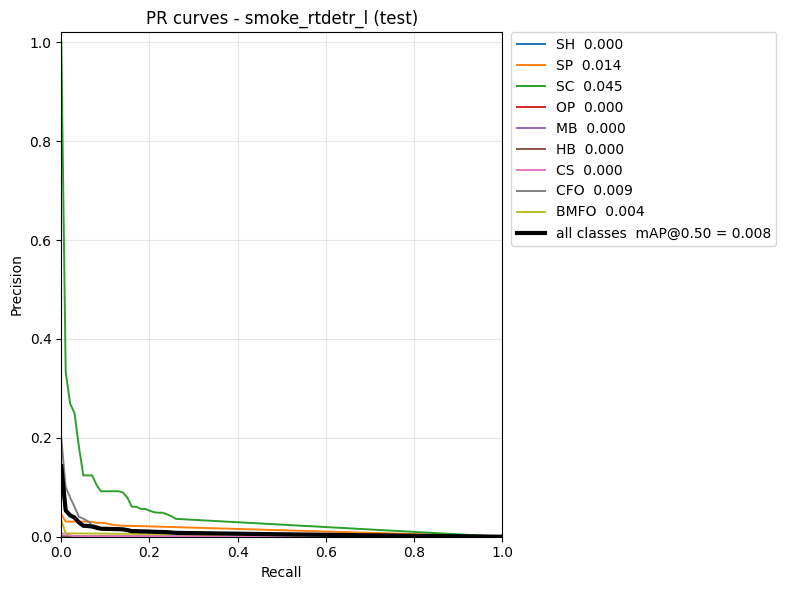

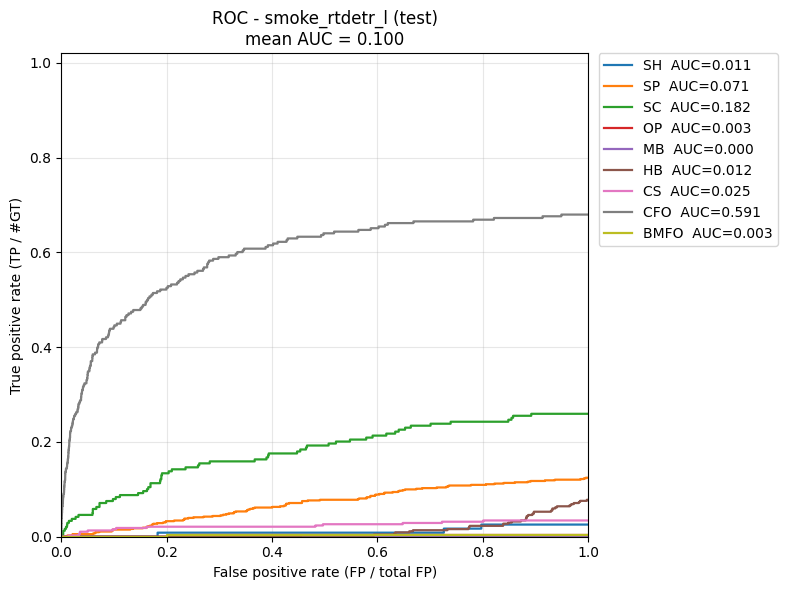

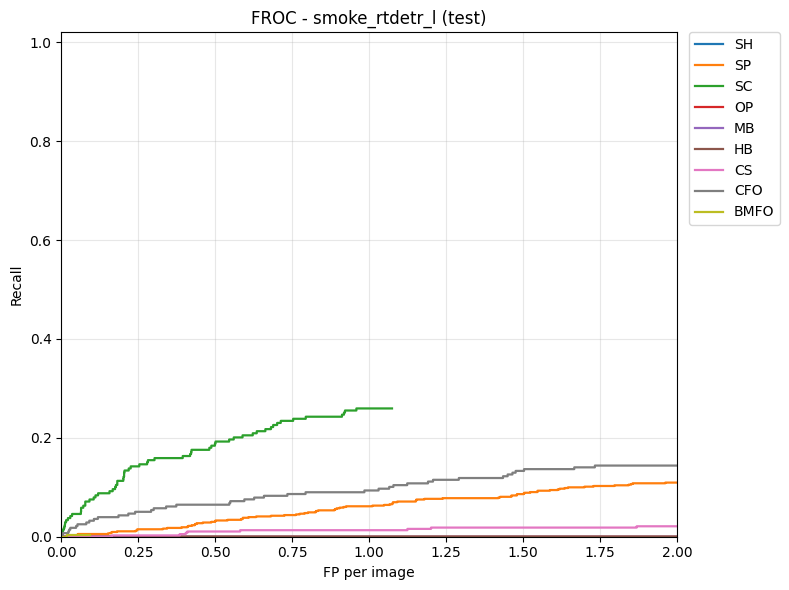

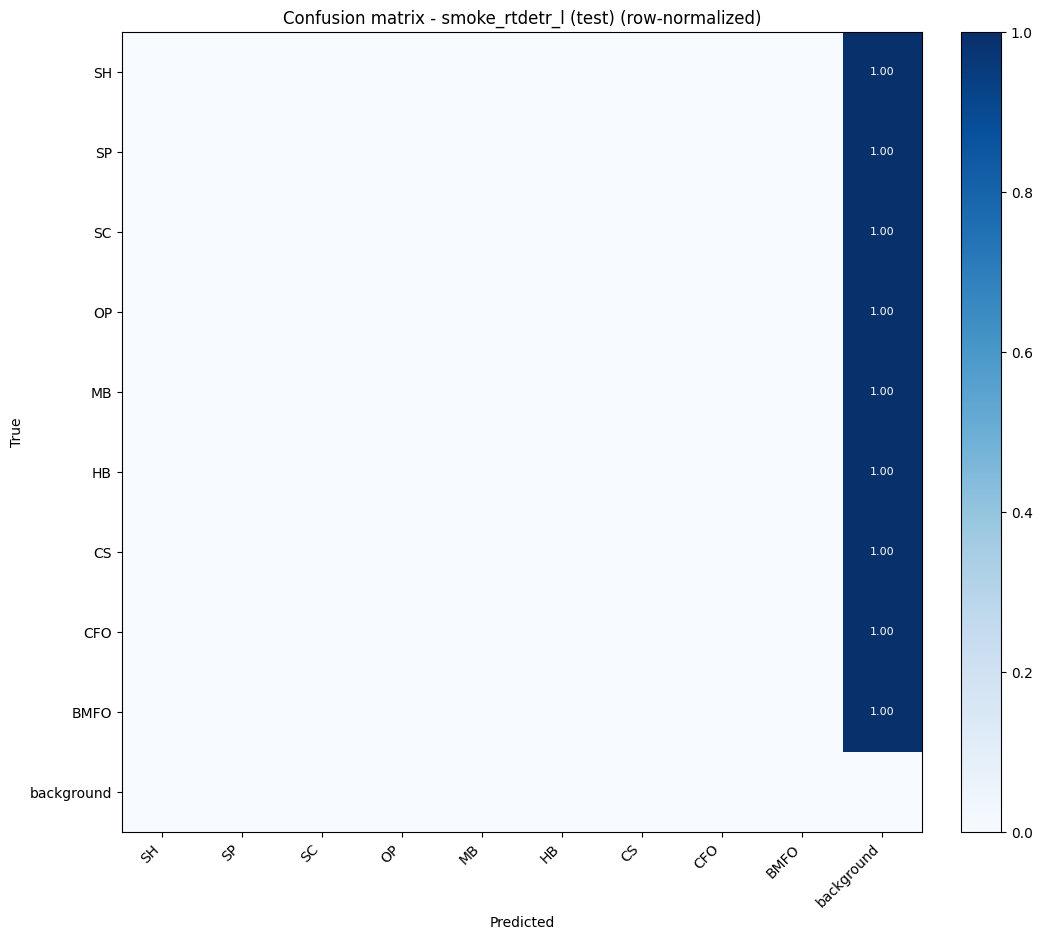

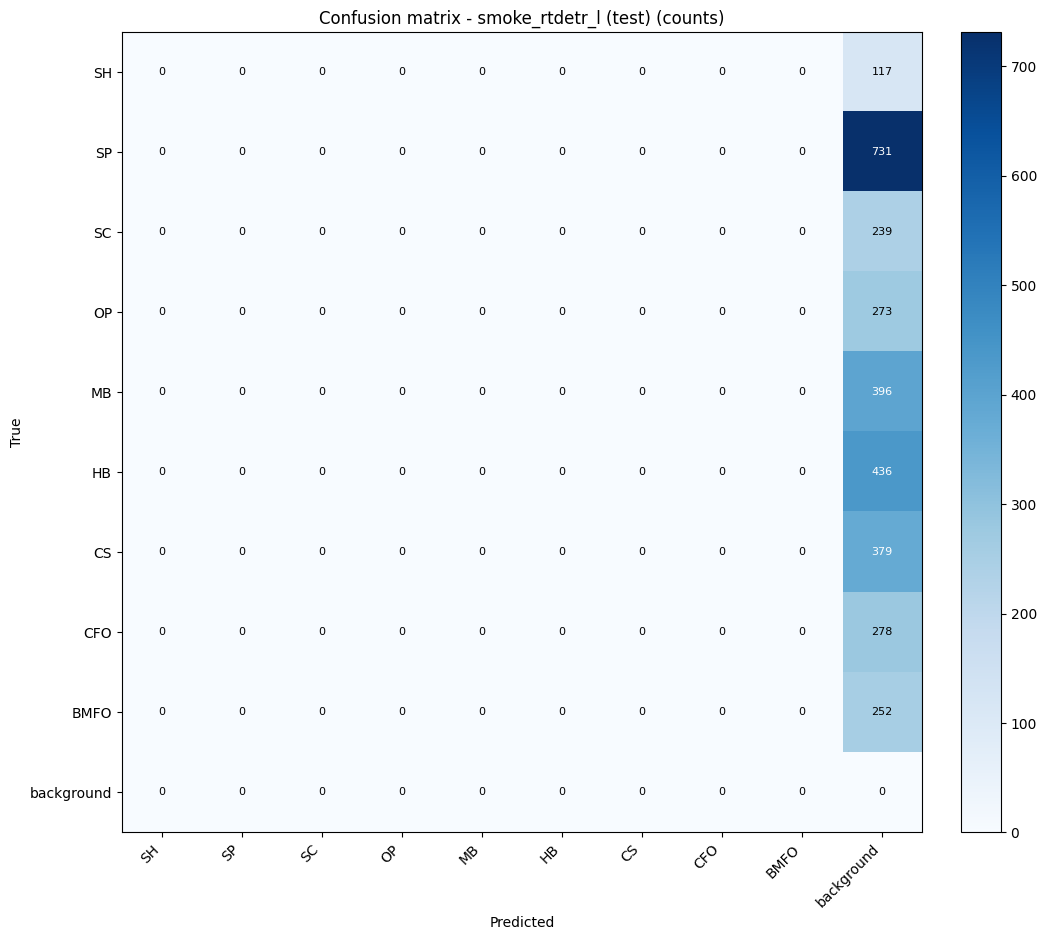

,AP50 (custom),AP50 (Ultralytics),chênh
SH,0.0000,0.0000,0.0000
SP,0.0137,0.0037,0.0100
SC,0.0451,0.0315,0.0136
OP,0.0000,0.0000,0.0000
MB,0.0000,0.0000,0.0000
HB,0.0003,0.0000,0.0002
CS,0.0005,0.0001,0.0004
CFO,0.0090,0.0087,0.0003
BMFO,0.0036,0.0002,0.0034


In [22]:
cur = U.evaluate_curves_for_model(model, DATA_YAML, split='test', imgsz=CFG['IMGSZ'], out_dir=FIG, tag=CFG['RUN_NAME'], conf_cm=0.25)
# Đối chiếu AP50 tự tính với Ultralytics (chênh nhỏ là bình thường; chênh lớn -> kiểm tra lại)
chk = pd.DataFrame({'AP50 (custom)': cur['AP50_custom'], 'AP50 (Ultralytics)': {k: v['AP50'] for k, v in res_test['per_class'].items()}})
chk['chênh'] = (chk.iloc[:, 0] - chk.iloc[:, 1]).abs()
display(chk.round(4))

## 7. Ảnh dự đoán mẫu

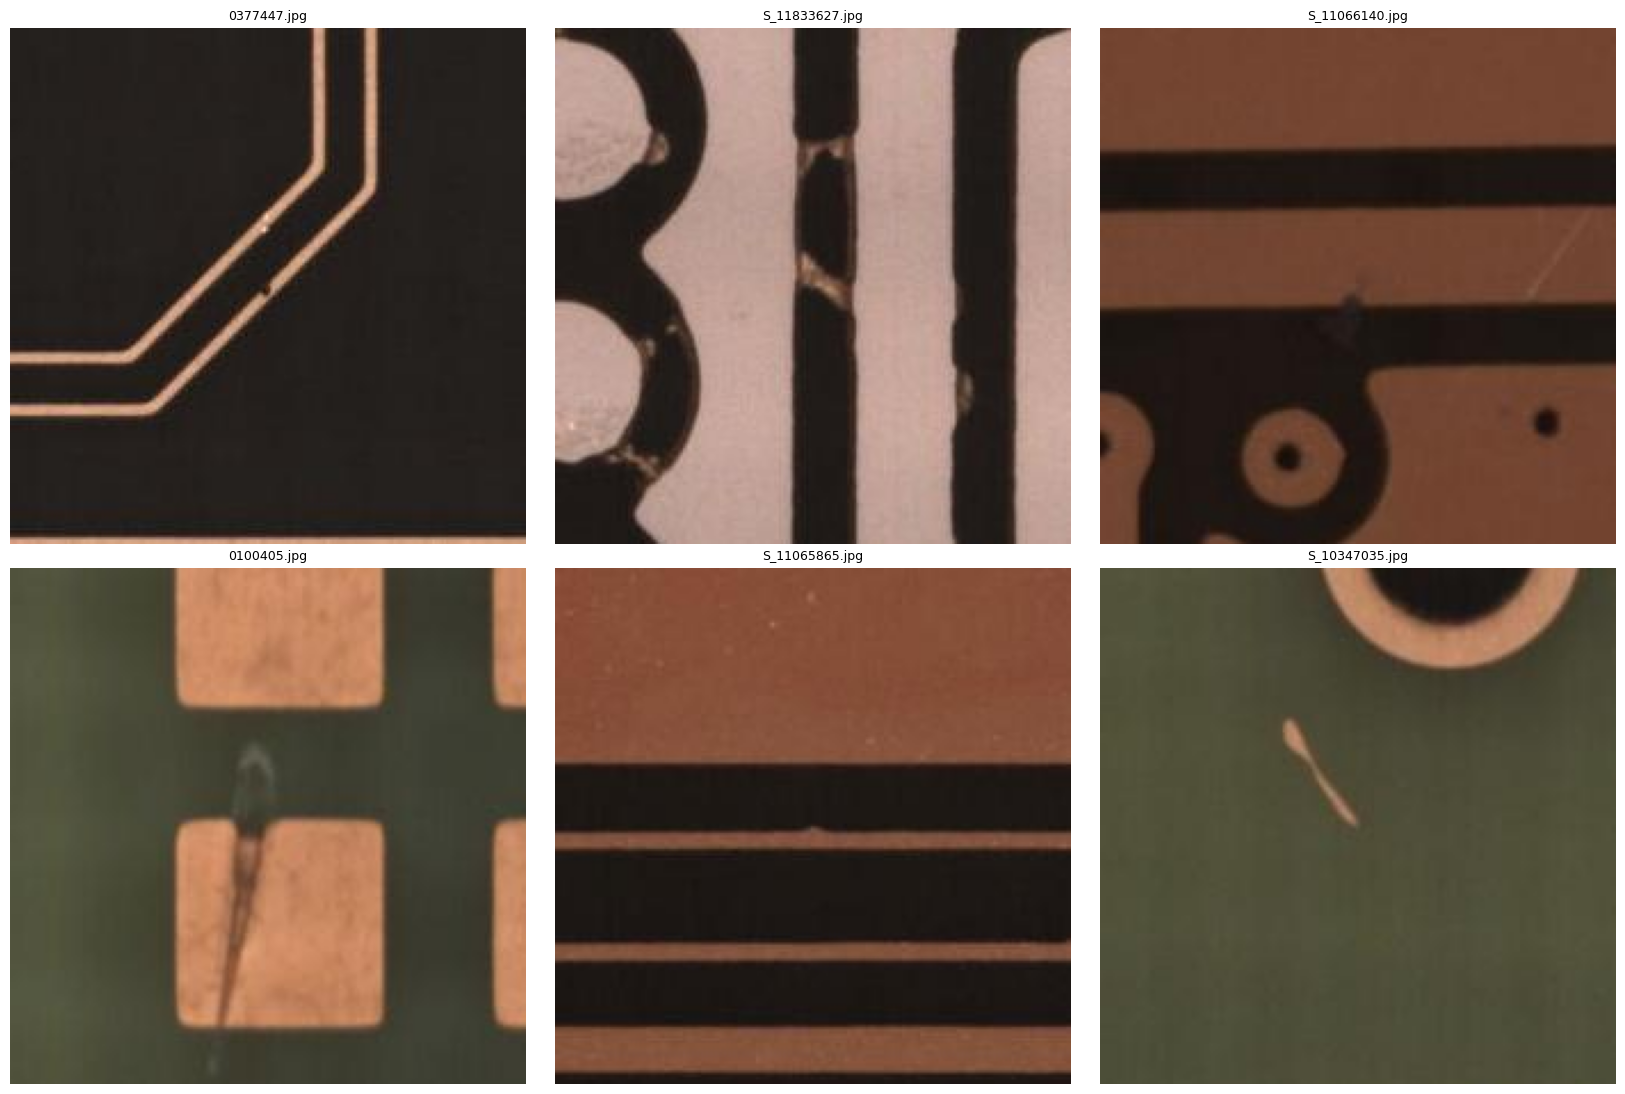

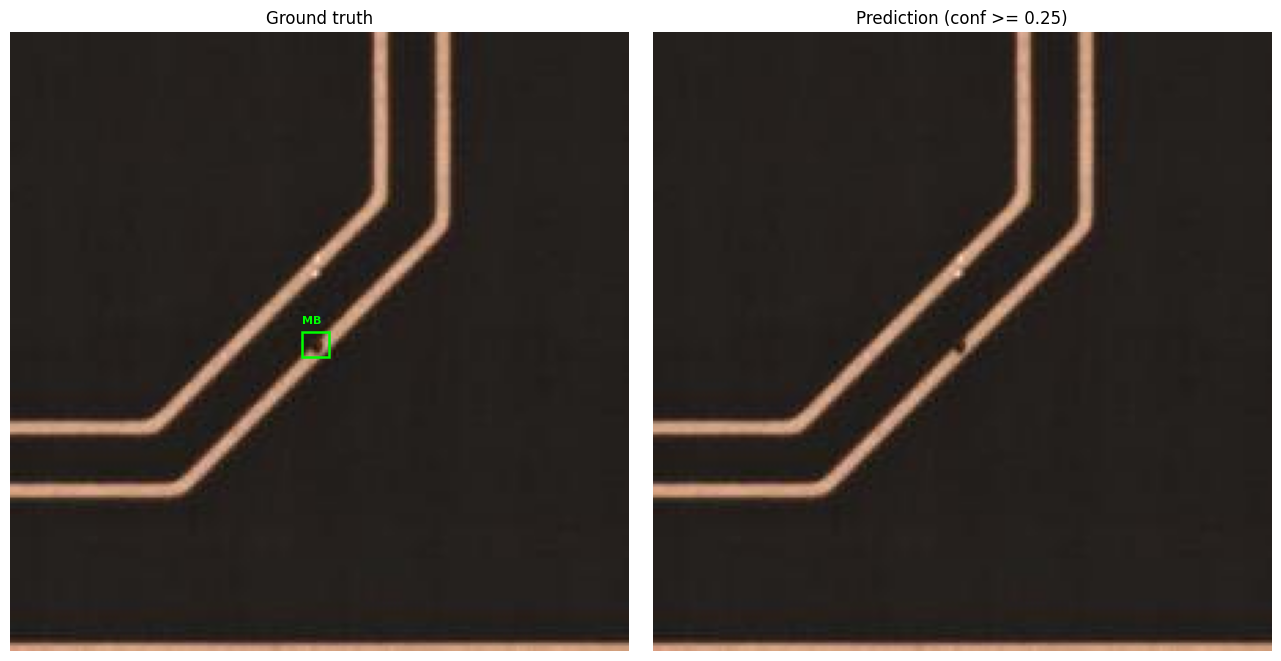

In [23]:
import random
test_imgs = list(test_imgs); random.Random(CFG['SEED']).shuffle(test_imgs)
U.show_predictions(model, test_imgs[:6], conf=0.25, imgsz=CFG['IMGSZ'], save_path=FIG / f"{CFG['RUN_NAME']}_samples.png")
U.plot_gt_vs_pred(model, test_imgs[0], NAMES, conf=0.25, imgsz=CFG['IMGSZ'], save_path=FIG / f"{CFG['RUN_NAME']}_gt_vs_pred.png")

## 8. Lưu kết quả để bàn giao
Xuất JSON (A gộp bảng ở Giai đoạn 5), CSV/Markdown bảng tổng hợp và nén toàn bộ biểu đồ + log + best.pt.

In [24]:
import shutil, json
OUT = Path(CFG['OUT_DIR'])
U.save_json({'cfg': {k: v for k, v in CFG.items()}, 'val': res_val, 'test': res_test, 'curves': {'AP50_custom': cur['AP50_custom'], 'AUC': cur['AUC']}},
            OUT / f"{CFG['RUN_NAME']}_results.json")
U.make_summary_table({CFG['RUN_NAME']: res_test}, save_csv=OUT / f"{CFG['RUN_NAME']}_summary.csv", save_md=OUT / f"{CFG['RUN_NAME']}_summary.md")
shutil.copy(best_pt, OUT / f"{CFG['RUN_NAME']}_best.pt")
shutil.copy(save_dir / 'results.csv', OUT / f"{CFG['RUN_NAME']}_results.csv")
shutil.make_archive('/kaggle/working/' + CFG['RUN_NAME'] + '_bundle', 'zip', OUT)
print('Đã lưu:', *sorted(p.name for p in OUT.iterdir()), sep='\n  ')

Đã lưu:
  eval
  figures
  smoke_rtdetr_l.log
  smoke_rtdetr_l_best.pt
  smoke_rtdetr_l_results.csv
  smoke_rtdetr_l_results.json
  smoke_rtdetr_l_summary.csv
  smoke_rtdetr_l_summary.md
  smoke_yolov8s.log
  smoke_yolov8s_best.pt
  smoke_yolov8s_results.csv
  smoke_yolov8s_results.json
  smoke_yolov8s_summary.csv
  smoke_yolov8s_summary.md


## Phụ lục – Gộp nhiều mô hình (dùng ở Giai đoạn 2 và 5)
Đặt các file `*_results.json` của từng mô hình vào cùng một thư mục rồi chạy:
```python
import json, glob
R = {Path(p).stem.replace('_results',''): json.load(open(p))['test'] for p in glob.glob('/kaggle/input/<ket-qua>/*_results.json')}
df = U.make_summary_table(R, save_csv='summary_all.csv', save_md='summary_all.md'); display(U.style_summary(df))
U.plot_model_comparison(df, save_path='compare_models.png')
U.plot_per_class_ap(U.per_class_table(R, 'AP50'), save_path='ap_per_class.png')
U.plot_compare_curves({n: f'<run>/{n}/results.csv' for n in R}, save_path='compare_map_curve.png')
```